This coding project aims to use machine learning, specifically Linear Regression, to predict future forest coverage in Indonesia based on historical data from 1990 to 2023. The dataset was obtained from Gapminder and contains forest coverage percentages over time.

By analyzing historical trends, the model will predict forest coverage for 2024 and the following 10 years. The model's performance will also be evaluated by comparing predicted values with actual data.

This project is related to **Sustainable Development Goal (SDG) 13: Climate Action**, as forests play an important role in absorbing carbon dioxide and reducing the effects of climate change.

#2. Load the Dataset


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "forest_coverage_percent.csv"
df = pd.read_csv(file_path)

df.head()


,geo,name,1990,1991,1992,1993,1994,1995,1996,1997,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,afg,Afghanistan,1.85,1.85,1.85,1.85,1.85,1.85,1.85,1.85,...,1.85,1.85,1.85,1.85,1.85,1.85,1.85,1.85,1.85,1.85
1,ago,Angola,63.58,63.45,63.33,63.20,63.08,62.95,62.83,62.71,...,56.10,55.65,55.21,54.76,54.32,53.87,53.43,52.98,52.54,52.09
2,alb,Albania,28.79,28.72,28.65,28.57,28.50,28.43,28.36,28.29,...,28.75,28.80,28.80,28.79,28.79,28.79,28.79,28.79,28.79,28.79
3,and,Andorra,34.04,34.04,34.04,34.04,34.04,34.04,34.04,34.04,...,34.04,34.04,34.04,34.04,34.04,34.04,34.04,34.04,34.04,34.04
4,are,UAE,3.45,3.54,3.63,3.72,3.81,3.90,3.99,4.08,...,4.47,4.47,4.47,4.47,4.47,4.47,4.47,4.47,4.47,4.47


## 3. Data Information

In [6]:

# Check the size of the dataset
print("Dataset shape:", df.shape)

# Check the column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Check the total number of missing values
print("\nMissing values:", df.isnull().sum().sum())


Dataset shape: (195, 36)

Column names:
['geo', 'name', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 36 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   geo     195 non-null    object 
 1   name    195 non-null    object 
 2   1990    160 non-null    float64
 3   1991    163 non-null    float64
 4   1992    182 non-null    float64
 5   1993    186 non-null    float64
 6   1994    186 non-null    float64
 7   1995    186 non-null    float64
 8   1996    186 non-null    float64
 9   1997    186 non-null    float64
 10  1998    186 non-null    float64
 11  1999    186 non-null    float64
 12  2000    188 non-null  

In [8]:

# Summary statistics for numeric columns
df.describe()

,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
count,160.000000,163.000000,182.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,...,191.000000,191.000000,191.000000,191.000000,191.000000,191.000000,191.000000,191.000000,191.000000,191.000000
mean,34.382375,35.073742,34.149505,33.925215,33.926882,33.877688,33.828280,33.779194,33.761452,33.712473,...,33.024712,32.982094,32.931623,32.885288,32.827435,32.768848,32.685654,32.629634,32.573665,32.515759
std,25.622628,25.998772,25.405822,25.145980,25.132516,25.071052,25.011128,24.953438,24.921797,24.868088,...,24.117364,24.079215,24.054030,24.031226,23.999237,23.969826,23.860698,23.833021,23.807840,23.783008
min,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,...,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000
25%,12.857500,12.830000,12.332500,12.332500,12.322500,12.257500,12.170000,12.080000,12.100000,12.110000,...,11.455000,11.450000,11.450000,11.445000,11.455000,11.510000,11.625000,11.545000,11.560000,11.595000
50%,29.840000,32.380000,31.835000,31.900000,32.055000,32.295000,32.195000,32.395000,32.725000,32.630000,...,31.260000,31.440000,31.620000,31.550000,31.700000,31.860000,32.120000,32.210000,32.320000,32.390000
75%,54.027500,55.860000,52.215000,52.257500,52.317500,52.192500,52.180000,52.180000,52.550000,52.550000,...,51.125000,50.775000,50.760000,50.325000,50.110000,50.015000,49.930000,49.840000,49.755000,49.550000
max,96.230000,95.930000,95.760000,95.740000,95.710000,95.690000,95.670000,95.650000,95.620000,95.600000,...,95.080000,95.020000,94.950000,94.910000,94.830000,94.750000,94.680000,94.600000,94.520000,94.450000


In [10]:
# Count missing values in each column
missing_counts = df.isna().sum()

print("Total missing values:", int(missing_counts.sum()))
print("\\nColumns with the most missing values:")
display(missing_counts.sort_values(ascending=False).head(10))

Total missing values: 263
\nColumns with the most missing values:


,0
1990,35
1991,32
1992,13
1993,9
1996,9
1997,9
1994,9
1995,9
1998,9
1999,9


In [11]:

# Check duplicate rows and country names
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate country/region names:", df["name"].duplicated().sum())

# Inspect country/region names
display(df[["geo", "name"]].head(10))


Duplicate rows: 0
Duplicate country/region names: 0


,geo,name
0,afg,Afghanistan
1,ago,Angola
2,alb,Albania
3,and,Andorra
4,are,UAE
5,arg,Argentina
6,arm,Armenia
7,atg,Antigua and Barbuda
8,aus,Australia
9,aut,Austria


## 4. Data Preprocessing

### 4.1 Identify the year columns

In [12]:

# Identify columns whose names represent years
year_cols = [col for col in df.columns if str(col).isdigit()]
year_cols = sorted(year_cols, key=lambda value: int(value))

print("First year:", year_cols[0])
print("Last year:", year_cols[-1])
print("Number of year columns:", len(year_cols))


First year: 1990
Last year: 2023
Number of year columns: 34


### 4.2 Convert year values to numeric


In [13]:

df_clean = df.copy()

for col in year_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Check missing values after conversion
print("Missing year values after numeric conversion:",
      int(df_clean[year_cols].isna().sum().sum()))


Missing year values after numeric conversion: 263


### 4.3 Calculate the total for each year

In [14]:

# Select Indonesia's forest coverage data
df_indonesia = df_clean[df_clean["name"] == "Indonesia"]

# Create a yearly time series
yearly = df_indonesia[year_cols].T.reset_index()

yearly.columns = ["Year", "Forest_Coverage"]

# Convert Year to integer
yearly["Year"] = yearly["Year"].astype(int)

# Remove missing values
yearly = yearly.dropna()

# Display the first five rows
yearly.head()


,Year,Forest_Coverage
0,1990,65.44
1,1991,64.48
2,1992,63.53
3,1993,62.58
4,1994,61.63


#5. Explore Historical Trends

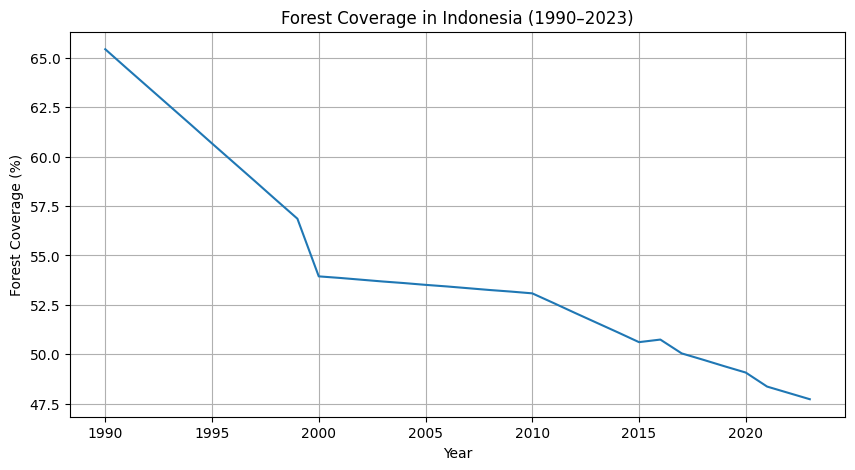

In [15]:

# Plot historical forest coverage in Indonesia
plt.figure(figsize=(10, 5))

plt.plot(yearly["Year"], yearly["Forest_Coverage"])

plt.title("Forest Coverage in Indonesia (1990–2023)")
plt.xlabel("Year")
plt.ylabel("Forest Coverage (%)")

plt.grid(True)
plt.show()


#6. Prepare Data for Linear Regression

In [18]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the most recent 30 available yearly observations
window_size = min(30, len(yearly))
recent_data = yearly.tail(window_size).reset_index(drop=True)

X_recent = recent_data[["Year"]]
y_recent = recent_data["Forest_Coverage"]

# Hold out the latest 5 years (or fewer if the dataset is short)
test_size = min(5, max(1, len(recent_data) // 5))
split_index = len(recent_data) - test_size

if split_index < 2:
    raise ValueError("There are not enough yearly observations to perform a chronological train-test split.")

X_train = X_recent.iloc[:split_index]
X_test = X_recent.iloc[split_index:]

y_train = y_recent.iloc[:split_index]
y_test = y_recent.iloc[split_index:]


print(f"Model window: {recent_data['Year'].min()}–{recent_data['Year'].max()}")
print(f"Training years: {X_train['Year'].min()}–{X_train['Year'].max()}")
print(f"Testing years: {X_test['Year'].min()}–{X_test['Year'].max()}")



Model window: 1994–2023
Training years: 1994–2018
Testing years: 2019–2023


## 7. Train and Evaluate the Model

In [19]:

evaluation_model = LinearRegression()
evaluation_model.fit(X_train, y_train)

test_predictions = evaluation_model.predict(X_test)

mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
r2 = r2_score(y_test, test_predictions)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")


MAE:  0.5984
RMSE: 0.6070
R²:   0.0579


In [20]:

# Compare actual and predicted values for the test period
test_results = pd.DataFrame({
    "Year": X_test["Year"].values,
    "Actual": y_test.values,
    "Predicted": test_predictions
})
test_results["Error"] = test_results["Actual"] - test_results["Predicted"]

display(test_results)


,Year,Actual,Predicted,Error
0,2019,49.39,48.7424,0.6476
1,2020,49.07,48.3300,0.7400
2,2021,48.36,47.9176,0.4424
3,2022,48.04,47.5052,0.5348
4,2023,47.72,47.0928,0.6272


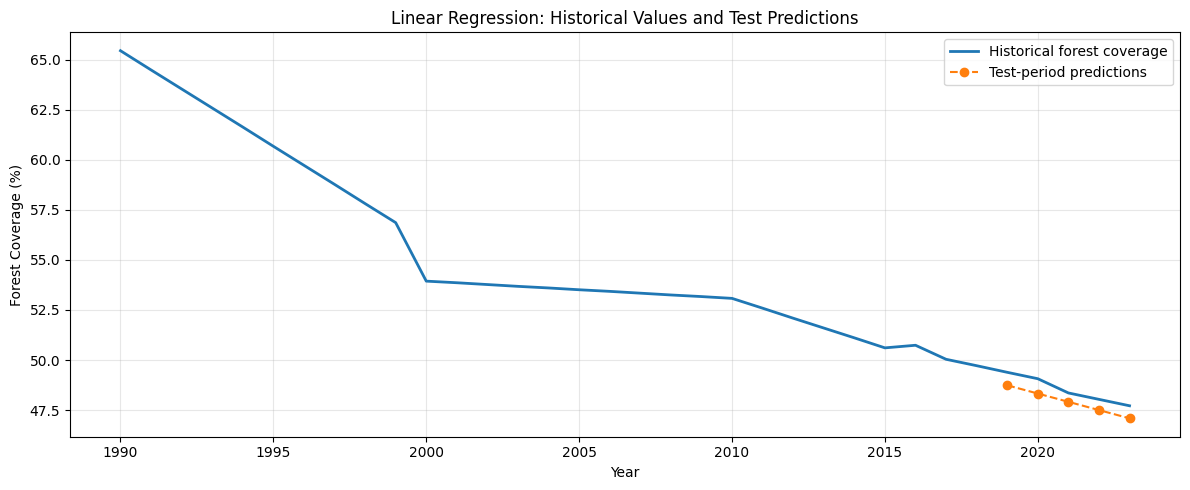

In [21]:

plt.figure(figsize=(12, 5))
plt.plot(yearly["Year"], yearly["Forest_Coverage"],
         label="Historical forest coverage", linewidth=2)
plt.plot(test_results["Year"], test_results["Predicted"],
         label="Test-period predictions", linestyle="--", marker="o")
plt.title("Linear Regression: Historical Values and Test Predictions")
plt.xlabel("Year")
plt.ylabel("Forest Coverage (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Train the final model and predict the next year



In [22]:

# Train the final model using all recent data
final_model = LinearRegression()
final_model.fit(X_recent, y_recent)

# Predict the next year
next_year = int(recent_data["Year"].max()) + 1
next_year_df = pd.DataFrame({"Year": [next_year]})

next_year_prediction = final_model.predict(next_year_df)[0]

print(f"Predicted forest coverage for {next_year}: {next_year_prediction:.2f}%")


Predicted forest coverage for 2024: 47.04%


## 9. Optional: Predict More Than One Year Ahead


,Year,Predicted_Forest_Coverage
0,2024,47.036368
1,2025,46.640499
2,2026,46.244630
3,2027,45.848762
4,2028,45.452893
5,2029,45.057024
6,2030,44.661155
7,2031,44.265287
8,2032,43.869418
9,2033,43.473549


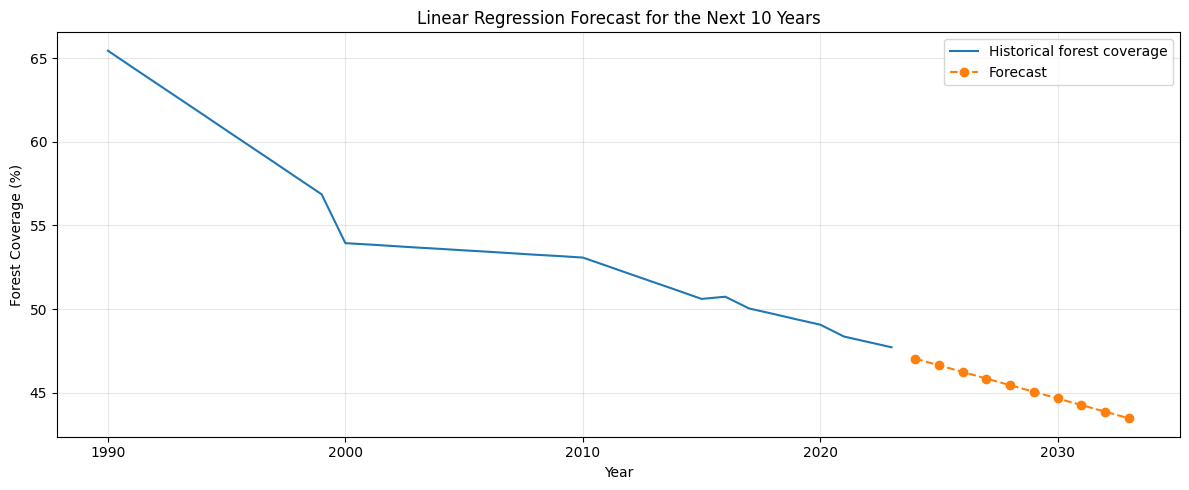

In [23]:

future_years = pd.DataFrame({
    "Year": range(next_year, next_year + 10)
})
future_years["Predicted_Forest_Coverage"] = final_model.predict(future_years[["Year"]])

display(future_years)

plt.figure(figsize=(12, 5))
plt.plot(yearly["Year"], yearly["Forest_Coverage"],
         label="Historical forest coverage")
plt.plot(future_years["Year"], future_years["Predicted_Forest_Coverage"],
         label="Forecast", linestyle="--", marker="o")
plt.title("Linear Regression Forecast for the Next 10 Years")
plt.xlabel("Year")
plt.ylabel("Forest Coverage (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 10. Conclusion

In this notebook, we:

1. Loaded and inspected the forest coverage dataset from Gapminder (1990–2023).
2. Checked data types, missing values, and duplicates.
3. Selected Indonesia's data and converted it into a yearly time series.
4. Visualized the historical forest coverage trend in Indonesia.
5. Evaluated Linear Regression using the latest 5 years (2019–2023), obtaining an MAE of 0.5984, RMSE of 0.6070, and R² of 0.0579.
6. Trained a final model using the most recent 30 years and predicted Indonesia's forest coverage in 2024 to be **47.04%**.
7. Forecasted forest coverage for the next 10 years (2024–2033).

## Limitations

- Missing values in the original dataset may affect the analysis.
- Linear Regression assumes a linear trend and may not capture sudden changes in forest coverage.
- The model does not consider future deforestation, reforestation, or government policies.
- The low R² score (0.0579) indicates that the model has limited ability to explain changes during the testing period.
- Predictions for future years may not be accurate because environmental conditions can change.

## Connection to SDG 13: Climate Action

This project supports SDG 13 by showing how machine learning can be used to monitor forest coverage trends. Forests help absorb carbon dioxide, so understanding changes in forest coverage is important for addressing climate change.